# 02 · EDA cech z klastra (T20)

Cel: zanim powstanie model (T23), sprawdzić na prawdziwym ruchu bazowym rozkłady, korelacje i sezonowość 9 cech z reguł nagrywających (`docs/architektura.md`, „Kontrakt metryk i logów”) oraz założenia danych syntetycznych z prototypu (`01-prototyp.ipynb`, T09).

Dane: co najmniej 2 h ruchu Locusta (T18) bez scenariuszy S1–S7, eksport `aiops.export` do `aiops/data/baseline.parquet` (katalog poza git):

```bash
make prometheus   # drugi terminal
uv run python -m aiops.export --from <ISO> --to <ISO> --out aiops/data/baseline.parquet
uv run jupyter nbconvert --to notebook --execute --inplace aiops/notebooks/02-eda.ipynb
```

Notebook z wynikami jest w git; po nowym eksporcie wyniki i wnioski się zmieniają.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aiops.features import FEATURE_COLUMNS, SERVICES, STEP_SECONDS, max_gap_seconds

pd.set_option("display.precision", 3)
# Niska rozdzielczość wykresów: notebook z wynikami jest w git.
plt.rcParams["figure.dpi"] = 60

DATA = Path("../data/baseline.parquet")  # katalog roboczy notebooka: aiops/notebooks
MIN_HOURS = 2  # kryterium T20
STEPS_PER_MIN = 60 // STEP_SECONDS

features = pd.read_parquet(DATA)
by_service = {service: features.xs(service, level="service") for service in SERVICES}
timestamps = features.index.get_level_values("timestamp")
first, last = timestamps.min(), timestamps.max()
hours = (last - first) / pd.Timedelta(hours=1)
assert hours >= MIN_HOURS, f"eksport ma {hours:.2f} h, potrzeba {MIN_HOURS} h"
print(f"{first} – {last}: {hours:.2f} h, krok {STEP_SECONDS} s")

2026-11-23 13:16:30+00:00 – 2026-11-23 15:16:30+00:00: 2.00 h, krok 30 s


## Dane i luki

Luka to kolejne kroki, w których brakuje którejkolwiek cechy (`aiops.features.max_gap_seconds`); kryterium T20: najwyżej 60 s. Cechy `http_*` bez ruchu mają 0 (reguła eksportu), więc brak wartości oznacza brak ewaluacji reguły.

In [2]:
pd.DataFrame(
    {
        "wiersze": {s: len(f) for s, f in by_service.items()},
        "wiersze z brakami": {
            s: int(f.isna().any(axis=1).sum()) for s, f in by_service.items()
        },
        "najdłuższa luka (s)": max_gap_seconds(features),
    }
)

,wiersze,wiersze z brakami,najdłuższa luka (s)
frontend,241,0,0
orders,241,0,0


## Przebiegi

Wszystkie cechy obu usług; oś x to minuty od początku eksportu.

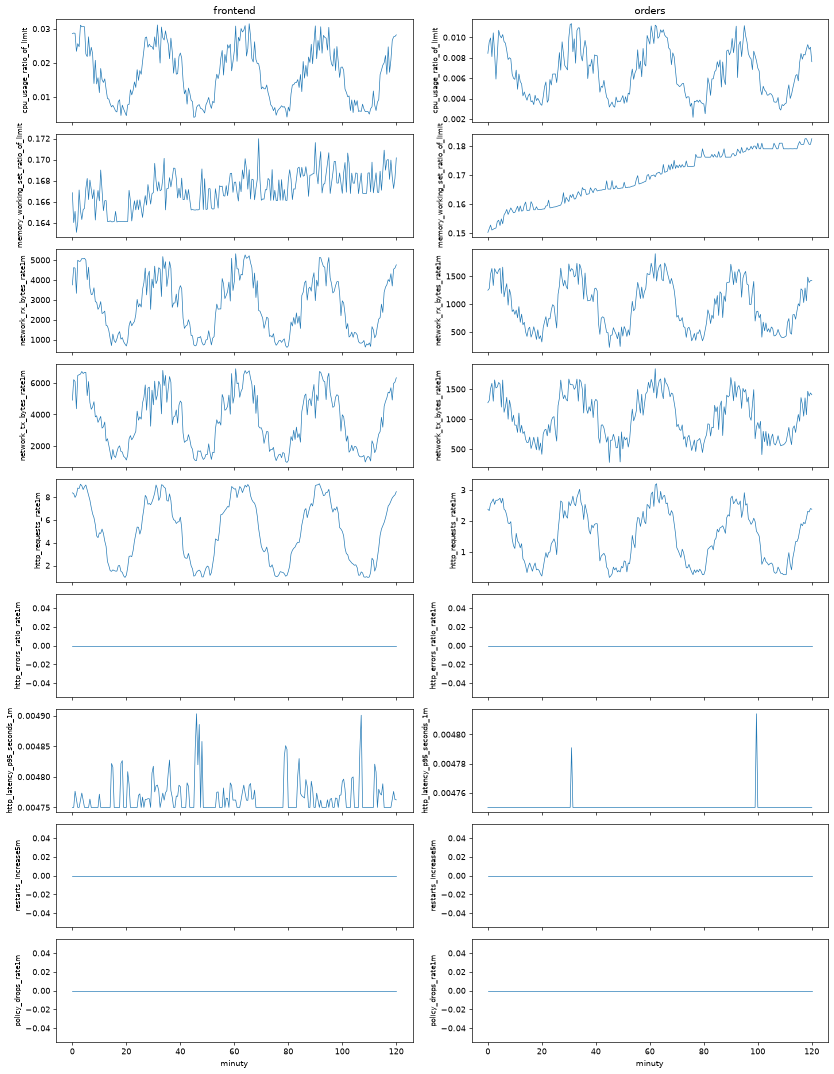

In [3]:
minutes = (by_service[SERVICES[0]].index - first) / pd.Timedelta(minutes=1)
fig, axes = plt.subplots(
    len(FEATURE_COLUMNS), len(SERVICES), figsize=(14, 18), sharex=True
)
for col, service in enumerate(SERVICES):
    axes[0, col].set_title(service)
    for row, feature in enumerate(FEATURE_COLUMNS):
        axes[row, col].plot(minutes, by_service[service][feature], linewidth=0.8)
        axes[row, col].set_ylabel(feature, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("minuty")
fig.tight_layout()

## Rozkłady

Statystyki i histogramy cech w ruchu bazowym. Cecha z odchyleniem 0 jest dla IsolationForest niewidoczna (`docs/detekcja.md`, „Dlaczego IsolationForest wypada słabo”).

In [4]:
pd.concat(
    {
        service: frame.describe(percentiles=[0.05, 0.5, 0.95]).T.assign(
            skew=frame.skew()
        )
        for service, frame in by_service.items()
    },
    names=["service", "cecha"],
)

count      mean        std  \
service  cecha                                                           
frontend cpu_usage_ratio_of_limit           241.0     0.017  8.133e-03   
         memory_working_set_ratio_of_limit  241.0     0.167  1.678e-03   
         network_rx_bytes_rate1m            241.0  2726.246  1.436e+03   
         network_tx_bytes_rate1m            241.0  3678.188  1.812e+03   
         http_requests_rate1m               241.0     5.037  2.811e+00   
         http_errors_ratio_rate1m           241.0     0.000  0.000e+00   
         http_latency_p95_seconds_1m        241.0     0.005  2.705e-05   
         restarts_increase5m                241.0     0.000  0.000e+00   
         policy_drops_rate1m                241.0     0.000  0.000e+00   
orders   cpu_usage_ratio_of_limit           241.0     0.007  2.395e-03   
         memory_working_set_ratio_of_limit  241.0     0.169  8.663e-03   
         network_rx_bytes_rate1m            241.0   979.092  4.334e+02   
         network_tx_bytes_rate1m            241.0  1041.336  3.760e+02   
         http_requests_rate1m               241.0     1.508  8.674e-01   
         http_errors_ratio_rate1m           241.0     0.000  0.000e+00   
         http_latency_p95_seconds_1m        241.0     0.005  4.895e-06   
         restarts_increase5m                241.0     0.000  0.000e+00   
         policy_drops_rate1m                241.0     0.000  0.000e+00   

                                                min        5%       50%  \
service  cecha                                                            
frontend cpu_usage_ratio_of_limit             0.004     0.006     0.017   
         memory_working_set_ratio_of_limit    0.163     0.164     0.167   
         network_rx_bytes_rate1m            610.565   734.723  2645.357   
         network_tx_bytes_rate1m            959.327  1208.164  3666.534   
         http_requests_rate1m                 0.956     1.089     5.200   
         http_errors_ratio_rate1m             0.000     0.000     0.000   
         http_latency_p95_seconds_1m          0.005     0.005     0.005   
         restarts_increase5m                  0.000     0.000     0.000   
         policy_drops_rate1m                  0.000     0.000     0.000   
orders   cpu_usage_ratio_of_limit             0.002     0.003     0.006   
         memory_working_set_ratio_of_limit    0.150     0.156     0.170   
         network_rx_bytes_rate1m            222.425   403.096   954.715   
         network_tx_bytes_rate1m            277.950   523.168   998.499   
         http_requests_rate1m                 0.178     0.311     1.533   
         http_errors_ratio_rate1m             0.000     0.000     0.000   
         http_latency_p95_seconds_1m          0.005     0.005     0.005   
         restarts_increase5m                  0.000     0.000     0.000   
         policy_drops_rate1m                  0.000     0.000     0.000   

                                                 95%       max    skew  
service  cecha                                                          
frontend cpu_usage_ratio_of_limit              0.030     0.032   0.119  
         memory_working_set_ratio_of_limit     0.170     0.172   0.018  
         network_rx_bytes_rate1m            5062.380  5319.794   0.134  
         network_tx_bytes_rate1m            6599.437  6904.303   0.135  
         http_requests_rate1m                  8.933     9.178  -0.039  
         http_errors_ratio_rate1m              0.000     0.000     NaN  
         http_latency_p95_seconds_1m           0.005     0.005   2.438  
         restarts_increase5m                   0.000     0.000     NaN  
         policy_drops_rate1m                   0.000     0.000     NaN  
orders   cpu_usage_ratio_of_limit              0.011     0.011   0.218  
         memory_working_set_ratio_of_limit     0.181     0.183  -0.232  
         network_rx_bytes_rate1m            1641.925  1903.822   0.159  
         network_tx_bytes_rate1m        

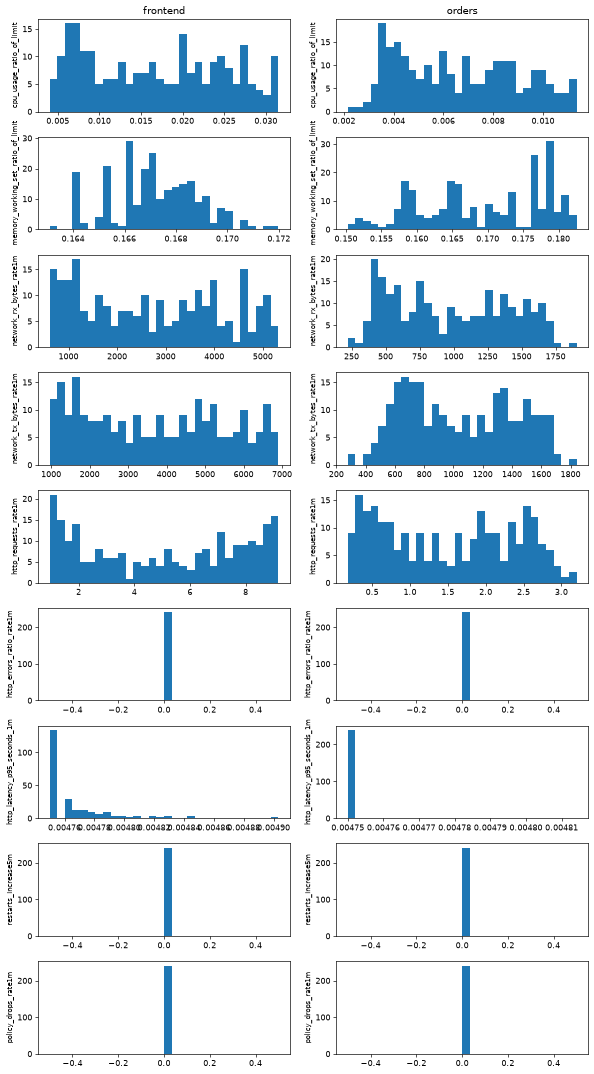

In [5]:
fig, axes = plt.subplots(len(FEATURE_COLUMNS), len(SERVICES), figsize=(10, 18))
for col, service in enumerate(SERVICES):
    axes[0, col].set_title(service)
    for row, feature in enumerate(FEATURE_COLUMNS):
        axes[row, col].hist(by_service[service][feature].dropna(), bins=30)
        axes[row, col].set_ylabel(feature, fontsize=8)
fig.tight_layout()

## Korelacje

Korelacja Spearmana (rangowa, odporna na pojedyncze piki) między cechami każdej usługi; puste pola to cechy stałe. Tabela pod wykresem: ta sama cecha we frontend i orders.

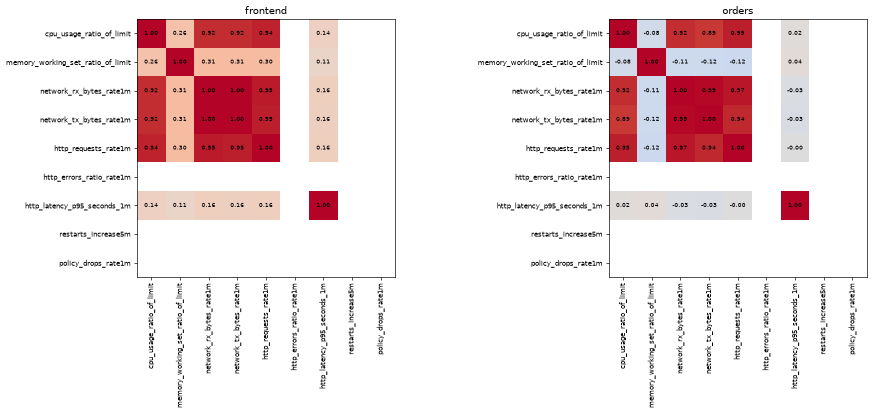

In [6]:
correlations = {
    service: frame.corr(method="spearman") for service, frame in by_service.items()
}
fig, axes = plt.subplots(1, len(SERVICES), figsize=(16, 7))
for ax, service in zip(axes, SERVICES):
    matrix = correlations[service]
    ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=90, fontsize=8)
    ax.set_yticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, fontsize=8)
    for i, j in np.ndindex(matrix.shape):
        if np.isfinite(matrix.iat[i, j]):
            ax.text(
                j, i, f"{matrix.iat[i, j]:.2f}", ha="center", va="center", fontsize=7
            )
    ax.set_title(service)
fig.tight_layout()

In [7]:
pd.Series(
    {
        feature: pd.concat([by_service[s][feature] for s in SERVICES], axis=1)
        .corr(method="spearman")
        .iat[0, 1]
        for feature in FEATURE_COLUMNS
    },
    name="Spearman frontend–orders",
)

cpu_usage_ratio_of_limit             0.902
memory_working_set_ratio_of_limit    0.583
network_rx_bytes_rate1m              0.924
network_tx_bytes_rate1m              0.889
http_requests_rate1m                 0.975
http_errors_ratio_rate1m               NaN
http_latency_p95_seconds_1m         -0.067
restarts_increase5m                    NaN
policy_drops_rate1m                    NaN
Name: Spearman frontend–orders, dtype: float64

## Sezonowość

Autokorelacja każdej cechy dla przesunięć do 60 min. Ruch Locusta ma okres 30 min (`docs/architektura.md`, „Ruch (Locust)”). Tabela: przesunięcie z najwyższą autokorelacją w zakresie 10–45 min; puste wiersze to cechy stałe.

okres (min)  autokorelacja
service  cecha                                                        
frontend cpu_usage_ratio_of_limit                  29.5          0.881
         memory_working_set_ratio_of_limit         26.0          0.505
         network_rx_bytes_rate1m                   30.0          0.884
         network_tx_bytes_rate1m                   30.0          0.877
         http_requests_rate1m                      30.0          0.958
         http_errors_ratio_rate1m                   NaN            NaN
         http_latency_p95_seconds_1m               27.5          0.168
         restarts_increase5m                        NaN            NaN
         policy_drops_rate1m                        NaN            NaN
orders   cpu_usage_ratio_of_limit                  29.5          0.850
         memory_working_set_ratio_of_limit         10.0          0.971
         network_rx_bytes_rate1m                   29.5          0.875
         network_tx_bytes_rate1m                   29.0          0.836
         http_requests_rate1m                      29.5          0.931
         http_errors_ratio_rate1m                   NaN            NaN
         http_latency_p95_seconds_1m               31.5         -0.006
         restarts_increase5m                        NaN            NaN
         policy_drops_rate1m                        NaN            NaN

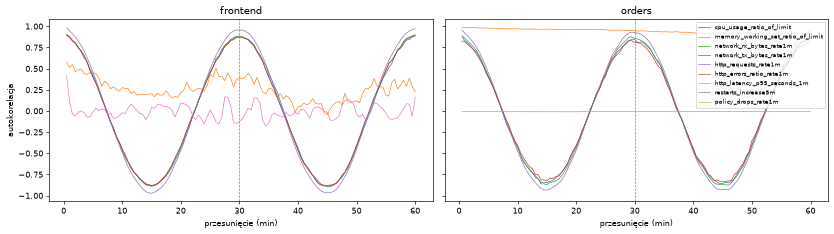

In [8]:
MAX_LAG_MIN = 60
PERIOD_SEARCH_MIN = (10, 45)
lags = np.arange(1, MAX_LAG_MIN * STEPS_PER_MIN + 1)
acf = {
    service: pd.DataFrame(
        {
            feature: [frame[feature].autocorr(int(lag)) for lag in lags]
            for feature in FEATURE_COLUMNS
        },
        index=pd.Index(lags / STEPS_PER_MIN, name="przesunięcie (min)"),
    )
    for service, frame in by_service.items()
}
fig, axes = plt.subplots(1, len(SERVICES), figsize=(14, 4), sharey=True)
for ax, service in zip(axes, SERVICES):
    acf[service].plot(ax=ax, linewidth=0.8, legend=False)
    ax.axvline(30, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(service)
axes[0].set_ylabel("autokorelacja")
axes[-1].legend(fontsize=7, loc="upper right")
fig.tight_layout()


def peak(frame: pd.DataFrame) -> pd.DataFrame:
    search = frame.loc[PERIOD_SEARCH_MIN[0] : PERIOD_SEARCH_MIN[1]]
    search = search.dropna(axis=1, how="all")
    return pd.DataFrame(
        {"okres (min)": search.idxmax(), "autokorelacja": search.max()}
    ).reindex(FEATURE_COLUMNS)


period = pd.concat(
    {service: peak(frame) for service, frame in acf.items()},
    names=["service", "cecha"],
)
period

## Założenia prototypu a dane

Poziomy i zależności, z których `01-prototyp.ipynb` (komórka „Model danych” i funkcja `simulate`) generował ruch bazowy, obok wartości z klastra. Wyraz wolny i nachylenie: prosta najmniejszych kwadratów cechy względem `http_requests_rate1m` tej samej usługi (p95 tylko z krokami z ruchem).

In [9]:
PROTOTYPE = {  # simulate() w 01-prototyp.ipynb, ruch bazowy
    "frontend": {
        "średni ruch (żądania/s)": 10.0,
        "CPU/limit: wyraz wolny": 0.04,
        "CPU/limit: na 1 żądanie/s": 0.009,
        "pamięć/limit (mediana)": 0.30,
        "B odebrane na żądanie (mediana)": 400.0,
        "B wysłane na żądanie (mediana)": 1600.0,
        "p95 (s): wyraz wolny": 0.03,
        "p95 (s): na 1 żądanie/s": 0.0008,
        "udział 5xx (średnia)": 0.001,
        "restarty i odrzucenia (maks.)": 0.0,
        "okres ruchu (min)": 30.0,
    },
    "orders": {
        "średni ruch (żądania/s)": 3.0,
        "CPU/limit: wyraz wolny": 0.03,
        "CPU/limit: na 1 żądanie/s": 0.01,
        "pamięć/limit (mediana)": 0.16,
        "B odebrane na żądanie (mediana)": 350.0,
        "B wysłane na żądanie (mediana)": 450.0,
        "p95 (s): wyraz wolny": 0.012,
        "p95 (s): na 1 żądanie/s": 0.0004,
        "udział 5xx (średnia)": 0.001,
        "restarty i odrzucenia (maks.)": 0.0,
        "okres ruchu (min)": 30.0,
    },
}


def line(x: pd.Series, y: pd.Series) -> tuple[float, float]:
    """Wyraz wolny i nachylenie prostej y = a + b·x (najmniejsze kwadraty)."""
    valid = x.notna() & y.notna()
    slope, intercept = np.polyfit(x[valid], y[valid], 1)
    return float(intercept), float(slope)


measured = {}
for service, frame in by_service.items():
    rps = frame["http_requests_rate1m"]
    busy = rps > 0
    cpu = line(rps, frame["cpu_usage_ratio_of_limit"])
    p95 = line(rps[busy], frame["http_latency_p95_seconds_1m"][busy])
    measured[service] = {
        "średni ruch (żądania/s)": rps.mean(),
        "CPU/limit: wyraz wolny": cpu[0],
        "CPU/limit: na 1 żądanie/s": cpu[1],
        "pamięć/limit (mediana)": frame["memory_working_set_ratio_of_limit"].median(),
        "B odebrane na żądanie (mediana)": (
            frame["network_rx_bytes_rate1m"][busy] / rps[busy]
        ).median(),
        "B wysłane na żądanie (mediana)": (
            frame["network_tx_bytes_rate1m"][busy] / rps[busy]
        ).median(),
        "p95 (s): wyraz wolny": p95[0],
        "p95 (s): na 1 żądanie/s": p95[1],
        "udział 5xx (średnia)": frame["http_errors_ratio_rate1m"].mean(),
        "restarty i odrzucenia (maks.)": frame[
            ["restarts_increase5m", "policy_drops_rate1m"]
        ]
        .max()
        .max(),
        "okres ruchu (min)": period.loc[
            (service, "http_requests_rate1m"), "okres (min)"
        ],
    }

share = (
    by_service["orders"]["http_requests_rate1m"].mean()
    / by_service["frontend"]["http_requests_rate1m"].mean()
)
print(f"udział ruchu orders/frontend: prototyp 0.30, klaster {share:.2f}")
assumptions = pd.concat(
    {
        service: pd.DataFrame(
            {"prototyp": PROTOTYPE[service], "klaster": measured[service]}
        ).assign(**{"klaster/prototyp": lambda t: t["klaster"] / t["prototyp"]})
        for service in SERVICES
    },
    axis=1,
)
assumptions

udział ruchu orders/frontend: prototyp 0.30, klaster 0.30


frontend                              \
                                  prototyp    klaster klaster/prototyp   
średni ruch (żądania/s)          1.000e+01  5.037e+00            0.504   
CPU/limit: wyraz wolny           4.000e-02  2.793e-03            0.070   
CPU/limit: na 1 żądanie/s        9.000e-03  2.759e-03            0.307   
pamięć/limit (mediana)           3.000e-01  1.671e-01            0.557   
B odebrane na żądanie (mediana)  4.000e+02  5.680e+02            1.420   
B wysłane na żądanie (mediana)   1.600e+03  7.589e+02            0.474   
p95 (s): wyraz wolny             3.000e-02  4.772e-03            0.159   
p95 (s): na 1 żądanie/s          8.000e-04 -1.058e-06           -0.001   
udział 5xx (średnia)             1.000e-03  0.000e+00            0.000   
restarty i odrzucenia (maks.)    0.000e+00  0.000e+00              NaN   
okres ruchu (min)                3.000e+01  3.000e+01            1.000   

                                    orders                              
                                  prototyp    klaster klaster/prototyp  
średni ruch (żądania/s)          3.000e+00  1.508e+00        5.027e-01  
CPU/limit: wyraz wolny           3.000e-02  2.645e-03        8.817e-02  
CPU/limit: na 1 żądanie/s        1.000e-02  2.624e-03        2.624e-01  
pamięć/limit (mediana)           1.600e-01  1.698e-01        1.061e+00  
B odebrane na żądanie (mediana)  3.500e+02  6.610e+02        1.889e+00  
B wysłane na żądanie (mediana)   4.500e+02  7.054e+02        1.568e+00  
p95 (s): wyraz wolny             1.200e-02  4.750e-03        3.958e-01  
p95 (s): na 1 żądanie/s          4.000e-04  3.039e-07        7.598e-04  
udział 5xx (średnia)             1.000e-03  0.000e+00        0.000e+00  
restarty i odrzucenia (maks.)    0.000e+00  0.000e+00              NaN  
okres ruchu (min)                3.000e+01  2.950e+01        9.833e-01

## Wnioski

- **Dane:** 2026-11-23 13:16:30 UTC – 2026-11-23 15:16:30 UTC (2,00 h), 241 kroków na usługę; najdłuższa luka: frontend 0 s, orders 0 s — kryterium T20 (≤ 60 s) spełnione.
- **Rozkłady:** cechy stałe w ruchu bazowym (odchylenie 0): frontend `http_errors_ratio_rate1m`, `restarts_increase5m`, `policy_drops_rate1m`, orders `http_errors_ratio_rate1m`, `restarts_increase5m`, `policy_drops_rate1m`; IsolationForest ich nie widzi (`docs/detekcja.md`). Największa |skośność|: frontend `http_latency_p95_seconds_1m` 2,438 i `network_tx_bytes_rate1m` 0,135, orders `http_latency_p95_seconds_1m` 11,662 i `memory_working_set_ratio_of_limit` −0,232.
- **Korelacje:** pary cech z |ρ| ≥ 0,8 — frontend: `cpu_usage_ratio_of_limit`–`network_rx_bytes_rate1m` 0,921, `cpu_usage_ratio_of_limit`–`network_tx_bytes_rate1m` 0,917, `cpu_usage_ratio_of_limit`–`http_requests_rate1m` 0,945, `network_rx_bytes_rate1m`–`network_tx_bytes_rate1m` 0,999, `network_rx_bytes_rate1m`–`http_requests_rate1m` 0,954, `network_tx_bytes_rate1m`–`http_requests_rate1m` 0,950; orders: `cpu_usage_ratio_of_limit`–`network_rx_bytes_rate1m` 0,918, `cpu_usage_ratio_of_limit`–`network_tx_bytes_rate1m` 0,889, `cpu_usage_ratio_of_limit`–`http_requests_rate1m` 0,951, `network_rx_bytes_rate1m`–`network_tx_bytes_rate1m` 0,989, `network_rx_bytes_rate1m`–`http_requests_rate1m` 0,965, `network_tx_bytes_rate1m`–`http_requests_rate1m` 0,937. Ta sama cecha we frontend i orders z |ρ| ≥ 0,8: `cpu_usage_ratio_of_limit` 0,902, `network_rx_bytes_rate1m` 0,924, `network_tx_bytes_rate1m` 0,889, `http_requests_rate1m` 0,975.
- **Sezonowość:** okres `http_requests_rate1m`: frontend 30,0 min, orders 29,5 min; autokorelacja w szczycie ≥ 0,5: frontend `cpu_usage_ratio_of_limit` 0,881, `memory_working_set_ratio_of_limit` 0,505, `network_rx_bytes_rate1m` 0,884, `network_tx_bytes_rate1m` 0,877, `http_requests_rate1m` 0,958; orders `cpu_usage_ratio_of_limit` 0,850, `memory_working_set_ratio_of_limit` 0,971, `network_rx_bytes_rate1m` 0,875, `network_tx_bytes_rate1m` 0,836, `http_requests_rate1m` 0,931. Okno treningowe 30 min (T23) obejmuje pełny okres ruchu.
- **Założenia prototypu:** różnica co najmniej 2× (`klaster/prototyp` poniżej 0,5 albo powyżej 2): CPU/limit, wyraz wolny (frontend): 0,04 → 0,0028; CPU/limit na 1 żądanie/s (frontend): 0,009 → 0,0028; B wysłane na żądanie, mediana (frontend): 1600 → 759; p95 (s), wyraz wolny (frontend): 0,03 → 0,0048; p95 (s) na 1 żądanie/s (frontend): 0,0008 → −1,1e-06; udział 5xx, średnia (frontend): 0,001 → 0; CPU/limit, wyraz wolny (orders): 0,03 → 0,0026; CPU/limit na 1 żądanie/s (orders): 0,01 → 0,0026; p95 (s), wyraz wolny (orders): 0,012 → 0,0048; p95 (s) na 1 żądanie/s (orders): 0,0004 → 3,0e-07; udział 5xx, średnia (orders): 0,001 → 0; udział ruchu orders/frontend: prototyp 0,30, klaster 0,30.